# 📡 LAB TOOLS &mdash; Extração de Parâmetros Elétricos (MOSFET)

---
Copyright (C) 2026 Roberto Baginski Batista Santos - Prof.Baginski@gmail.com

Este programa é um software livre; você pode redistribuí-lo e/ou
modificá-lo sob os termos da Licença Pública Geral GNU como publicada
pela Free Software Foundation; tanto a versão 3 da Licença, ou
(a seu critério) qualquer versão posterior.

Este programa é distribuído na expectativa de que seja útil,
mas SEM NENHUMA GARANTIA; sem mesmo a garantia implícita de
COMERCIALIZAÇÃO ou de ADEQUAÇÃO A QUALQUER PROPÓSITO EM PARTICULAR.
Veja a Licença Pública Geral GNU para mais detalhes.

Você deve ter recebido uma cópia da Licença Pública Geral GNU junto
com este programa. Se não, veja https://www.gnu.org/licenses/gpl-3.0.html.

---
Esta ferramenta extrai **parâmetros elétricos de um MOSFET** a partir da curva de transferência $I_\mathrm{D} \times V_\mathrm{G}$ medida com tensão dreno-fonte $V_\mathrm{D}$ fixa.

**Pré-processamento**

Para reduzir as flutuações aleatórias, os pontos experimentais são suavizados pelo **filtro de Savitzky-Golay** implementado no pacote `SciPy` com uma janela de 15 pontos e polinômios de grau 3 (estes valores podem ser alterados na interface).

A transcodutância $g_m=dI_\mathrm{D}/dV_\mathrm{G}$ e sua derivada $d^2I_\mathrm{D}/dV_\mathrm{G}^2$ são calculadas pelo próprio filtro, derivando o polinômio local usado para suavização.

Na região de sublimiar, em que a variação de $I_\mathrm{D}$ abrange muitas décadas, o filtro é aplicado também a $\log_{10}|I_\mathrm{D}|$. Nos casos em que há valores repetidos de $V_\mathrm{G}$, como em uma varredura de ida e volta, é usada a média dos valores de $I_\mathrm{D}$ para os dois valores de $V_\mathrm{G}$; se a amostragem não for uniforme, a ferramenta executa uma reamostragem uniforme sobre os dados.

**A) Estimativa da tensão de limiar $V_\mathrm{T}$**

A tensão de limiar $V_\mathrm{T}$ é estimada pelos seguintes métodos:

1. **Método da Corrente Constante (CC)**: $V_\mathrm{T}$ é o valor de $V_\mathrm{G}$ em que $I_\mathrm{D} = I_{\mathrm{D-CC}} = I_\mathrm{CC}W/L$, em que $W$ e $L$ são, respectivamente, a largura e o comprimento de máscara do canal do dispositivo.
2. **Método da Segunda Derivada (SDM)**: $V_\mathrm{T}$ é o valor de $V_\mathrm{G}$ em que $d^2I_\mathrm{D}/dV_\mathrm{G}^2$ atinge seu valor máximo.
3. **Método da Extrapolação na Região Linear (ELR)**: $V_\mathrm{T} = V_\mathrm{G-ELR} - V_\mathrm{D}/2$ em que $V_\mathrm{G-ELR}$ é o valor de $V_\mathrm{G}$ do ponto em que a reta tangente à curva $I_\mathrm{D}\times V_\mathrm{G}$ no ponto de transcondutância máxima intercepta o eixo $V_\mathrm{G}$.
4. **Método da função $Y$ de Ghibaudo**: $V_\mathrm{T} = V_\mathrm{G-Y}$, em que $V_\mathrm{G-Y}$ é o valor de $V_\mathrm{G}$ do ponto em que a função $Y = I_\mathrm{D}/\sqrt{g_m} = \sqrt{\beta V_\mathrm{D}}\,(V_\mathrm{G} - V_\mathrm{T})$ intercepta o eixo $V_\mathrm{G}$.

No **regime de saturação** os métodos ELR e SDM são aplicados a $\sqrt{I_\mathrm{D}}$, e $V_\mathrm{T} = V_\mathrm{GI}$.

**B) Transcondutância máxima**: $g_{mm}$ é o valor máximo da transcondutância $g_m = dI_\mathrm{D}/dV_\mathrm{G}$.

**C) Sublimiar**:
1. **Inclinação de Sublimiar** (Subthreshold Slope): $S$ é o valor máximo de $d\log_{10}I_\mathrm{D}/dV_\mathrm{G}$ (em déc/V), obtido pelo ajuste linear de $\log_{10}|I_\mathrm{D}|$ sobre uma década de corrente.
2. **Oscilação de Sublimiar** (Subthreshold Swing): $SS = 1/S$ (em mV/déc).
3. **Fator de Idealidade**: $n = SS/(k_\mathrm{B}T\ln(10)/e)$, em que $k_\mathrm{B}$ é a constante de Boltzmann e $e$ é a carga elementar.

Para validação dos resultados, leve em conta que, comumente:
 - $SS\geq SS_\mathrm{min} = k_\mathrm{B}T\ln(10)/e$
   - $SS_\mathrm{min} \approx 59{,}5$ mV/déc para $T=300\,\mathrm{K}$ (limite termiônico);
 - o fator de idealidade $n\geq 1$.


**E) Grandezas adicionais**

1. **Função Y de Ghibaudo**: a função $Y = I_\mathrm{D}/\sqrt{g_m} = \sqrt{\beta V_\mathrm{D}}\,(V_\mathrm{G} - V_\mathrm{T})$ é linear no regime de inversão forte e pouco sensível à degradação da mobilidade, permitindo estimar a tensão de limiar $V_\mathrm{T}$, o fator de ganho da transcondutância $\beta=\mu_0 C_\mathrm{ox}W/L$, em que $C_\mathrm{ox} = \varepsilon_\mathrm{r}\varepsilon_0/t_\mathrm{ox}$ é a capacitância por unidade de área, e o fator de degradação da mobilidade $\theta$ (obtido a partir de $1/\sqrt{g_m} = (1+\theta (V_\mathrm{G}-V_\mathrm{T}))/\sqrt{\beta V_\mathrm{D}}$).
2. **Mobilidade**: se a espessura $t_\mathrm{ox}$ do óxido for informada, a ferramenta estima:
    - Mobilidade em Campo Baixo (Low-Field Mobility): $\mu_0 = \beta L/W C_\mathrm{ox}$.
    - Mobilidade de Efeito de Campo (Field-Effect Mobility): $\mu_\mathrm{FE} = Lg_{mm}/W C_\mathrm{ox} V_\mathrm{D}$
3. **Eficiência da transcondutância**: $g_m/I_\mathrm{D} = d\ln I_\mathrm{D}/dV_\mathrm{G}$, que é, comumente, limitada por $\ln(10)/SS_\mathrm{min}=e/k_\mathrm{B}T$.
4. **Razão** $I_\mathrm{on}/I_\mathrm{off}$.

Campos que não forem preenchidos desativam os métodos que dependem destas informações. Assim, se $W$, $L$ e $I_\mathrm{CC}$ (ou $I_\mathrm{D-CC}$) não forem informados, o método `CC` não será usado e se $V_\mathrm{D}$ não for informado, o método `ELR` não será usado.

---
**Como usar:**
Execute a **Célula 1** — a interface aparece logo abaixo.

---
### Formatos de arquivo aceitos

| Formato | Extensão |
|---|---|
| XLSX - Planilha do Excel | `.xlsx` |
| CSV - Valores separados por vírgula | `.csv` `.txt` |

Cada grandeza ocupa uma coluna; as colunas de $V_G$ e $I_D$ são escolhidas na interface. Os valores podem usar `.` ou `,` como separador decimal. No formato `CSV`, se usar `,` como separador decimal, use `;` como separador de valores.

As unidades podem ser indicadas no cabeçalho, no formato `Rótulo (unidade)`, ou numa linha de comentário `# unidades:` antes dos dados:

```
 # unidades: V, nA
 V_G (V); I_D (nA)
 -0,50; 0,00021
 ...
```

Unidades reconhecidas: $V_\mathrm{G}$ em `V` ou `mV`; correntes de `fA` a `A` (`fA`, `pA`, `nA`, `µA` ou `uA`, `mA`, `A`); $W$ e $L$ em `nm` ou `µm`. Se as unidades não estiverem no arquivo, faça as escolhas correspondentes na interface.

Transistores **pMOS** são detectados automaticamente, mas a interface permite informar o tipo de transistor analisado; os resultados são apresentados com o sinal original de $V_\mathrm{G}$.


---
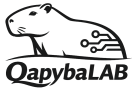

**https://github.com/rbaginski/QapybaLAB**

In [ ]:
#@title Execute esta célula para abrir a ferramenta **LAB TOOLS &mdash; Extração de Parâmetros Elétricos (MOSFET)**
# ── Célula 1: extração de parâmetros elétricos de MOSFET ────────────────────────────────
# A ferramenta foi especificada pelo licenciante, incluindo métodos, pacotes a
# serem usados e linhas gerais da interface gráfica; a maior parte do código foi
# escrita usando o modelo Claude Opus 5.5 e validada com curvas sintéticas
# (modelo EKV com degradação de mobilidade) de parâmetros conhecidos. O código
# gerado foi inspecionado e sofreu alterações e correções realizadas pelo
# licenciante.

import math, io, re, base64, unicodedata, warnings
import numpy as np
from scipy.signal import savgol_filter
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

warnings.filterwarnings("ignore")
matplotlib.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ══════════════════════════════════════════════════════════════════
#  CONSTANTES FÍSICAS (SI 2019 exatas; ε₀ CODATA 2022)
# ══════════════════════════════════════════════════════════════════
K_B  = 1.380649e-23        # J/K
Q_E  = 1.602176634e-19     # C
EPS0 = 8.8541878188e-12    # F/m

# ══════════════════════════════════════════════════════════════════
#  UNIDADES (fatores para o SI)
# ══════════════════════════════════════════════════════════════════
FATOR_I = {"fA":1e-15,"pA":1e-12,"nA":1e-9,"µA":1e-6,"mA":1e-3,"A":1.0}
FATOR_V = {"mV":1e-3,"V":1.0}
FATOR_C = {"nm":1e-9,"µm":1e-6}          # comprimentos W, L
ALIAS_UNID = {"ua":"µA","μa":"µA","µa":"µA","um":"µm","μm":"µm","µm":"µm",
              "fa":"fA","pa":"pA","na":"nA","ma":"mA","a":"A",
              "mv":"mV","v":"V","nm":"nm"}

def normalizar_unidade(u):
    """'uA' → 'µA', 'mv' → 'mV' etc. Retorna None se não reconhecida."""
    if u is None: return None
    s=str(u).strip().replace("μ","µ")
    if s in FATOR_I or s in FATOR_V or s in FATOR_C: return s
    return ALIAS_UNID.get(s.lower())

PREFIXOS = [(1e-15,"f"),(1e-12,"p"),(1e-9,"n"),(1e-6,"µ"),(1e-3,"m"),(1.0,"")]

def prefixo_para(vmax):
    """Escolhe o prefixo SI adequado para exibir valores até vmax."""
    v=abs(float(vmax)) if np.isfinite(vmax) else 1.0
    esc=PREFIXOS[0]
    for f,p in PREFIXOS:
        if v>=f*0.999: esc=(f,p)
    return esc

def fmt_sig(v,sig=4):
    v=float(v)
    if not math.isfinite(v) or v==0: return str(v)
    d=int(math.floor(math.log10(abs(v))))-(sig-1)
    return (f"{round(v,-d):.{max(0,-d)}f}" if d>=0 else f"{v:.{-d}f}")

def fmt_si(v,unidade,sig=4):
    """Formata com prefixo SI: 3.2e-6, 'A' → '3.200 µA'."""
    f,p=prefixo_para(v)
    return f"{fmt_sig(v/f,sig)} {p}{unidade}"

def nome_para_arquivo(nome):
    nfd=unicodedata.normalize("NFD",nome)
    return "".join(c for c in nfd if unicodedata.category(c)!="Mn").replace(" ","_")

# ══════════════════════════════════════════════════════════════════
#  LEITURA DE ARQUIVOS
# ══════════════════════════════════════════════════════════════════
def para_float(s):
    """Converte string em float aceitando ',' ou '.' como separador decimal."""
    t=str(s).strip().replace(" ","")
    if t=="": raise ValueError("célula vazia")
    if "," in t and "." in t:              # 1.234,5  ou  1,234.5
        if t.rfind(",")>t.rfind("."): t=t.replace(".","").replace(",",".")
        else: t=t.replace(",","")
    else:
        t=t.replace(",",".")
    return float(t)

def eh_numero(s):
    try: para_float(s); return True
    except Exception: return False

def parse_rotulo_unidade(texto):
    """'I_D (nA)' → ('I_D','nA');  'tensão' → ('tensão','')."""
    texto=str(texto).strip()
    m=re.match(r'^(.*?)\s*[\(\[]([^()\[\]]*)[\)\]]\s*$',texto)
    if m and m.group(1).strip(): return m.group(1).strip(),m.group(2).strip()
    return texto,''

def extrair_metadados(linha):
    """Reconhece '# unidades: V, A' e '# rótulos: V_G, I_D'."""
    s=str(linha).strip()
    if not s.startswith('#'): return None,None
    s=s.lstrip('#').strip()
    if ':' not in s: return None,None
    chave,resto=s.split(':',1)
    chave=unicodedata.normalize("NFD",chave.strip().lower())
    chave="".join(c for c in chave if unicodedata.category(c)!="Mn")
    valores=[v.strip() for v in re.split(r'[,;\t]',resto) if v.strip()!='']
    if not valores: return None,None
    if chave in ('unidades','unidade','units','unit'): return 'unidades',valores
    if chave in ('rotulos','rotulo','labels','label'): return 'rotulos',valores
    return None,None

def detectar_sep(texto):
    """Prioridade: ';' → TAB → ',' → espaço. (Com ';' a vírgula é decimal.)"""
    linhas=[l for l in texto.splitlines() if l.strip() and not l.strip().startswith('#')][:15]
    for sep in (";","\t"):
        if any(sep in l for l in linhas): return sep
    if any("," in l for l in linhas): return ","
    return " "

def dividir(linha,sep):
    return [p.strip() for p in linha.split(sep)] if sep!=" " else linha.split()

def ler_texto(texto,sep=None):
    """Retorna (linhas_validas, cabecalho, meta, sep)."""
    if sep is None: sep=detectar_sep(texto)
    meta={}; linhas=[]
    for l in texto.splitlines():
        if not l.strip(): continue
        if l.strip().startswith('#'):
            k,v=extrair_metadados(l)
            if k: meta[k]=v
            continue
        linhas.append(dividir(l,sep))
    cab=None
    if linhas and any(c and not eh_numero(c) for c in linhas[0]):
        cab=linhas[0]; linhas=linhas[1:]
    return linhas,cab,meta,sep

def ler_xlsx(conteudo):
    import openpyxl
    wb=openpyxl.load_workbook(io.BytesIO(conteudo),data_only=True)
    ws=wb.active
    meta={}; linhas=[]
    for row in ws.iter_rows(values_only=True):
        cells=['' if c is None else (repr(c) if isinstance(c,float) else str(c)).strip() for c in row]
        while cells and cells[-1]=='': cells.pop()
        if not cells: continue
        if cells[0].startswith('#'):
            k,v=extrair_metadados(cells[0] if len(cells)==1 else ", ".join(c for c in cells if c))
            if k: meta[k]=v
            continue
        linhas.append(cells)
    cab=None
    if linhas and any(c and not eh_numero(c) for c in linhas[0]):
        cab=linhas[0]; linhas=linhas[1:]
    return linhas,cab,meta

def extrair_colunas(linhas,cv,ci):
    vg=[]; idd=[]; erros=[]
    for k,cells in enumerate(linhas,1):
        try:
            if max(cv,ci)>=len(cells): raise IndexError("coluna ausente")
            a=para_float(cells[cv]); b=para_float(cells[ci])
            if not (math.isfinite(a) and math.isfinite(b)): raise ValueError("valor não finito")
            vg.append(a); idd.append(b)
        except Exception as e:
            erros.append(f"Linha de dados {k}: {e}")
    return np.array(vg,float),np.array(idd,float),erros

# ══════════════════════════════════════════════════════════════════
#  PRÉ-PROCESSAMENTO
# ══════════════════════════════════════════════════════════════════
def detectar_tipo(vg,idd):
    """nMOS se a maior |I_D| ocorre no extremo positivo de V_G; pMOS caso contrário."""
    i=int(np.argmax(np.abs(idd)))
    return "pMOS" if vg[i]<np.median(vg) and vg[i]<0 else "nMOS"

def preparar(vg,idd,tipo):
    """Converte para a convenção de nMOS: x = s·V_G, y = |I_D|, com x crescente.
    Pontos com V_G repetido (ex.: varredura ida e volta) são promediados."""
    s=-1.0 if tipo=="pMOS" else 1.0
    x=s*vg; y=np.abs(idd)
    o=np.argsort(x,kind="mergesort"); x=x[o]; y=y[o]
    xu,inv=np.unique(x,return_inverse=True)
    n_dup=len(x)-len(xu)
    if n_dup:
        yu=np.bincount(inv,weights=y)/np.bincount(inv); x,y=xu,yu
    return s,x,y,n_dup

def uniformizar(x,y):
    """Savitzky-Golay pressupõe passo constante. Se o passo variar mais que 5 %,
    os dados são reamostrados (interpolação linear) numa grade uniforme com o
    mesmo número de pontos."""
    dx=np.diff(x); h=float(np.median(dx))
    if np.max(np.abs(dx-h))/h<=0.05: return x,y,h,False
    xg=np.linspace(x[0],x[-1],len(x)); yg=np.interp(xg,x,y)
    return xg,yg,float(xg[1]-xg[0]),True

def refinar_parabola(x,f,i):
    """Posição e valor do extremo por parábola nos pontos i-1, i, i+1."""
    if i<=0 or i>=len(f)-1: return float(x[i]),float(f[i])
    y0,y1,y2=f[i-1],f[i],f[i+1]; den=y0-2*y1+y2
    if den==0: return float(x[i]),float(y1)
    d=0.5*(y0-y2)/den
    if abs(d)>1: return float(x[i]),float(y1)
    h=x[i+1]-x[i]
    return float(x[i]+d*h),float(y1-0.25*(y0-y2)*d)

# ══════════════════════════════════════════════════════════════════
#  EXTRAÇÃO DE PARÂMETROS
# ══════════════════════════════════════════════════════════════════
def extrair(x,y,h,janela,ordem,regime,VD=None,Icc=None,W=None,L=None,
            tox=None,eps_r=3.9,T=300.0):
    """Todas as grandezas em SI e na convenção de nMOS (x = s·V_G, y = |I_D|).
    Retorna dicionário com curvas e resultados; métodos sem dados → motivo."""
    R={"avisos":[],"VT":{},"pulado":{}}
    phi_t=K_B*T/Q_E; R["phi_t"]=phi_t
    sg=lambda v,d=0: savgol_filter(v,janela,ordem,deriv=d,delta=h,mode="interp")

    # ── Suavização da curva linear (pedido principal) ────────────────────
    Is=sg(y); gm=sg(y,1); d2=sg(y,2)
    R.update(Is=Is,gm=gm,d2=d2)

    # ── Suavização em log10|I_D| (sublimiar, corrente constante, gm/I_D) ─
    pos=y[y>0]; piso=(pos.min()*0.5) if pos.size else 1e-18
    ly=np.log10(np.maximum(y,piso))
    lys=sg(ly); dly=sg(ly,1)                    # dly em déc/V
    R.update(lys=lys,dly=dly,piso=piso)

    # ── Curva usada por ELR/SDM: I_D (linear) ou √I_D (saturação) ───────
    if regime=="Saturação":
        sq=np.sqrt(y); f=sg(sq); f1=sg(sq,1); f2=sg(sq,2)
    else:
        f,f1,f2=Is,gm,d2
    R.update(f=f,f1=f1,f2=f2)

    # ── B) Transcondutância máxima ───────────────────────────────────────
    # Busca dos máximos restrita ao interior (os hw pontos de cada borda têm
    # derivadas de maior variância no filtro de Savitzky-Golay).
    hw=janela//2; ini,fim=hw,len(x)-hw
    arg_int=lambda v: ini+int(np.argmax(v[ini:fim]))
    ig=arg_int(gm); Vgm,gmm=refinar_parabola(x,gm,ig)
    R.update(gmm=gmm,V_gmm=Vgm,I_gmm=float(np.interp(Vgm,x,Is)))
    if ig>=fim-2:
        R["avisos"].append("g<sub>m</sub> máximo ocorre na borda superior da varredura: "
                           "g<sub>mm</sub> pode estar subestimado (estenda a varredura de V<sub>G</sub>).")

    i1=arg_int(f1); V1,f1m=refinar_parabola(x,f1,i1)
    f_V1=float(np.interp(V1,x,f))

    # ── A3) Extrapolação linear (ELR) ────────────────────────────────────
    V_int=V1-f_V1/f1m
    R["ELR"]={"V_int":V_int,"V1":V1,"f_V1":f_V1,"f1m":f1m}
    if regime=="Saturação":
        R["VT"]["ELR"]=V_int
    elif VD is None:
        R["pulado"]["ELR"]=(f"V<sub>D</sub> não informado (intercepto V<sub>GI</sub> = "
                            f"{fmt_sig(V_int,4)} V; V<sub>T</sub> = V<sub>GI</sub> − V<sub>D</sub>/2)")
    else:
        R["VT"]["ELR"]=V_int-VD/2

    # ── A2) Segunda derivada (SDM) ───────────────────────────────────────
    m=x<=V1+1e-12
    if m.sum()>=3:
        m[:ini]=False
        idx=np.where(m)[0] if m.any() else np.array([0]); i2=idx[int(np.argmax(f2[idx]))]
        V2,f2m=refinar_parabola(x,f2,i2)
        if i2<=ini:
            R["pulado"]["SDM"]="máximo de d²/dV² na borda inferior da varredura"
        else:
            R["VT"]["SDM"]=V2; R["SDM"]={"V":V2,"f2m":f2m}
    else:
        R["pulado"]["SDM"]="poucos pontos antes do máximo de g<sub>m</sub>"

    # ── A1) Corrente constante ───────────────────────────────────────────
    if Icc is None:
        R["pulado"]["CC"]="I<sub>CC</sub>, W ou L (ou I<sub>D-CC</sub>) não informados"
    else:
        L0=math.log10(Icc); dd=lys-L0
        cr=np.where((dd[:-1]<0)&(dd[1:]>=0))[0]
        if cr.size:
            k=int(cr[-1])   # último cruzamento ascendente: imune ao ruído do patamar
            t=-dd[k]/(dd[k+1]-dd[k])
            R["VT"]["CC"]=float(x[k]+t*(x[k+1]-x[k]))
        else:
            R["pulado"]["CC"]=(f"I<sub>D-CC</sub> = {fmt_si(Icc,'A')} fora do intervalo de "
                               f"correntes medido ({fmt_si(10**lys.min(),'A')} – "
                               f"{fmt_si(10**lys.max(),'A')})")

    # ── C) Sublimiar ─────────────────────────────────────────────────────
    # Região: abaixo de V_T (SDM, ou V_G de g_mm) e pelo menos 1,5 década acima
    # do patamar de ruído (estimado pelo 10º percentil de log10|I_D| suavizado).
    x_ub=R["VT"].get("SDM",Vgm)
    ref=float(np.percentile(lys,10))+1.5
    R["sub_ref"]=ref; R["sub_xub"]=x_ub
    # (i) valor principal: ajuste linear de log10|I_D| (dados) sobre 1 década
    melhor=None
    for i in range(len(x)):
        if lys[i]<ref or x[i]>x_ub: continue
        j=np.where((x>x[i])&(lys>=lys[i]+1.0))[0]
        if not j.size or x[j[0]]>x_ub+1e-12: break
        j=int(j[0])
        if j-i+1>=3:
            a,b=np.polyfit(x[i:j+1],ly[i:j+1],1)
        else:
            Vf=float(np.interp(lys[i]+1.0,lys[i:j+1],x[i:j+1])); a=1.0/(Vf-x[i])
            b=lys[i]-a*x[i]
        if a>0 and (melhor is None or a>melhor[0]): melhor=(a,b,i,j)
    # (ii) valor local: máximo de d(log10 I_D)/dV_G da curva suave
    ms=(x<=x_ub)&(lys>=ref)&(dly>0)
    loc=None
    if ms.sum()>=3:
        idx=np.where(ms)[0]; i3=idx[int(np.argmax(dly[ms]))]
        loc=refinar_parabola(x,dly,i3)
    SS_ideal=1e3*math.log(10)*phi_t
    if melhor is not None or loc is not None:
        if melhor is not None:
            a,b,i,j=melhor; Smax=a; V1d,V2d=float(x[i]),float(x[j]); metodo="1 década"
        else:
            Smax=loc[1]; b=float(np.interp(loc[0],x,lys))-Smax*loc[0]
            V1d=V2d=loc[0]; metodo="local"
            R["avisos"].append("Menos de uma década de corrente disponível no sublimiar: "
                               "SS obtido da derivada local da curva suave.")
        SS=1e3/Smax; Vm_=0.5*(V1d+V2d)
        R["sub"]={"S":Smax,"SS":SS,"b":b,"V1":V1d,"V2":V2d,"V":Vm_,
                  "I":10**(b+Smax*Vm_),"n":SS/SS_ideal,"SS_ideal":SS_ideal,
                  "metodo":metodo,
                  "SS_loc":(1e3/loc[1] if loc else None),"V_loc":(loc[0] if loc else None)}
    else:
        R["sub"]=None
        R["avisos"].append("Região de sublimiar não identificada (dados sem decaimento "
                           "exponencial acima do patamar de ruído e abaixo de V<sub>T</sub>).")

    # ── E) Grandezas adicionais ──────────────────────────────────────────
    R["gm_ID"]=math.log(10)*dly                # gm/I_D = d ln I_D / dV_G  (1/V)
    R["Imax"]=float(10**lys[-1]); R["Imin"]=float(10**lys.min())
    R["Ion_Ioff"]=R["Imax"]/R["Imin"]

    Cox=None
    if tox: Cox=eps_r*EPS0/tox; R["Cox"]=Cox
    geo=(W is not None and L is not None)
    if Cox and geo:
        if regime=="Saturação":
            R["mu_FE"]=2*L*f1m**2/(W*Cox)
        elif VD is not None:
            R["mu_FE"]=L*gmm/(W*Cox*VD)

    # Função Y (Ghibaudo): Y = I_D/√g_m = √(β V_D)(V_G − V_T) — regime linear
    if regime=="Linear":
        Vref=R["VT"].get("SDM",Vgm)
        for lim in (Vgm,0.5*(Vref+Vgm)):
            mY=(x>=lim)&(gm>0)&(Is>0)
            if mY.sum()>=5: break
        if mY.sum()>=5:
            Y=Is[mY]/np.sqrt(gm[mY]); a,b=np.polyfit(x[mY],Y,1)
            VTY=-b/a
            c,_=np.polyfit(x[mY],1/np.sqrt(gm[mY]),1)
            R["Y"]={"mask":mY,"a":a,"b":b,"V_int":VTY,"theta":c*a}
            R["VT"]["Y"]=VTY-VD/2
#            if VD is not None: R["VT"]["Y"]=VTY-VD/2
#            else: R["pulado"]["Y"]=(f"V<sub>D</sub> não informado (intercepto da função Y = "
#                                    f"{fmt_sig(VTY,4)} V; V<sub>T</sub> = intercepto − V<sub>D</sub>/2)")
            if VD is not None:
                beta=a**2/VD; R["Y"]["beta"]=beta
                if Cox and geo: R["Y"]["mu0"]=beta*L/(W*Cox)
        else:
            R["pulado"]["Y"]="poucos pontos em inversão forte"
    return R

# ══════════════════════════════════════════════════════════════════
#  GRÁFICOS  (matplotlib → PNG base64 → <img>)
# ══════════════════════════════════════════════════════════════════
COR_AC="#9c36b5"                                   # acento desta ferramenta
COR_VT={"CC":"#2f9e44","SDM":"#e67700","ELR":"#3b5bdb","Y":"#c2255c"}
NOME_VT={"CC":"CC","SDM":"SDM","ELR":"ELR","Y":"Função Y"}
COR_BRUTO="#868e96"

def fig_b64(fig):
    buf=io.BytesIO()
    fig.savefig(buf,format="png",dpi=130,bbox_inches="tight")
    plt.close(fig); buf.seek(0)
    return base64.b64encode(buf.read()).decode()

def img_html(b64):
    return (f'<img src="data:image/png;base64,{b64}" style="width:100%;max-width:980px;'
            f'border-radius:6px;box-shadow:0 2px 8px rgba(0,0,0,.12);margin:6px 0">')

def _estilo(ax):
    ax.grid(True,ls="--",alpha=.4); ax.set_facecolor("#fafafa")

def _linhas_vt(ax,R,s,todas=True):
    for k,v in R["VT"].items():
        ax.axvline(s*v,color=COR_VT[k],lw=1.1,ls=":",
                   label=f"$V_T$ ({NOME_VT[k]}) = {s*v:.3f} V")

def figura_transferencia(D,R):
    s=D["s"]; x=D["x"]; y=D["y"]; xr=D["xr"]; yr=D["yr"]
    xp=s*x; xrp=s*xr
    nI="|I_D|" if s<0 else "I_D"; ng="|g_m|" if s<0 else "g_m"
    fI,pI=prefixo_para(np.max(R["Is"]))
    fg,pg=prefixo_para(R["gmm"])
    fig,axs=plt.subplots(2,2,figsize=(11.5,8.2))
    fig.subplots_adjust(hspace=.32,wspace=.26)

    # (a) I_D linear
    ax=axs[0,0]
    ax.plot(xrp,yr/fI,"o",ms=3,color=COR_BRUTO,alpha=.6,label="Dados")
    ax.plot(xp,R["Is"]/fI,color=COR_AC,lw=2,label="Savitzky-Golay")
    if D["regime"]=="Linear":
        e=R["ELR"]; xt=np.linspace(e["V_int"],x[-1],50)
        ax.plot(s*xt,(e["f_V1"]+e["f1m"]*(xt-e["V1"]))/fI,"--",color=COR_VT["ELR"],lw=1.3,
                label="Tangente em $g_{mm}$")
        ax.plot(s*e["V1"],e["f_V1"]/fI,"s",color=COR_VT["ELR"],ms=6)
    _linhas_vt(ax,R,s)
    ax.set_ylim(bottom=min(0,np.min(R["Is"]/fI)*1.05))
    ax.set_xlabel("$V_G$ (V)"); ax.set_ylabel(f"${nI}$ ({pI}A)")
    ax.set_title(f"(a) ${nI}$ × $V_G$ — escala linear",fontsize=10)
    ax.legend(fontsize=7.5,framealpha=.9); _estilo(ax)

    # (b) I_D log
    ax=axs[0,1]
    m=yr>0
    ax.semilogy(xrp[m],yr[m],"o",ms=3,color=COR_BRUTO,alpha=.6,label="Dados")
    ax.semilogy(xp,10**R["lys"],color=COR_AC,lw=2,label="Savitzky-Golay (log)")
    if D.get("Icc"):
        ax.axhline(D["Icc"],color=COR_VT["CC"],lw=1.1,ls="--",
                   label=f"$I_{{D\\text{{-}}CC}}$ = {fmt_si(D['Icc'],'A',3)}")
    sb=R["sub"]
    if sb:
        xt=np.linspace(sb["V1"]-.6*(sb["V2"]-sb["V1"]+.05),sb["V2"]+.6*(sb["V2"]-sb["V1"]+.05),40)
        ax.semilogy(s*xt,10**(sb["b"]+sb["S"]*xt),"--",color="#1a1a2e",lw=1.2,
                    label=f"SS = {sb['SS']:.1f} mV/déc")
    _linhas_vt(ax,R,s)
    lo=max(np.percentile(yr[m],1)/3 if m.any() else 1e-15,1e-18)
    ax.set_ylim(lo,np.max(yr)*3)
    ax.set_xlabel("$V_G$ (V)"); ax.set_ylabel(f"${nI}$ (A)")
    ax.set_title(f"(b) ${nI}$ × $V_G$ — escala logarítmica",fontsize=10)
    ax.legend(fontsize=7.5,framealpha=.9,loc="lower right"); _estilo(ax)

    # (c) g_m linear
    ax=axs[1,0]
    gr=np.gradient(yr,xr)
    ax.plot(xrp,gr/fg,"o",ms=2.5,color=COR_BRUTO,alpha=.45,label="Derivada numérica dos dados")
    ax.plot(xp,R["gm"]/fg,color=COR_AC,lw=2,label="Derivada Savitzky-Golay")
    ax.plot(s*R["V_gmm"],R["gmm"]/fg,"*",color="#c92a2a",ms=13,zorder=5,
            label=f"$g_{{mm}}$ = {fmt_si(R['gmm'],'S',4)} em $V_G$ = {s*R['V_gmm']:.3f} V")
    top=R["gmm"]/fg*1.25; ax.set_ylim(-0.08*top,top)
    ax.set_xlabel("$V_G$ (V)"); ax.set_ylabel(f"${ng}$ ({pg}S)")
    ax.set_title(f"(c) ${ng}$ × $V_G$ — escala linear",fontsize=10)
    ax.legend(fontsize=7.5,framealpha=.9); _estilo(ax)

    # (d) g_m log
    ax=axs[1,1]
    mg=R["gm"]>0
    ax.semilogy(xp[mg],R["gm"][mg],color=COR_AC,lw=2,label="$g_m$ (suavização linear)")
    gl=R["gm_ID"]*10**R["lys"]; ml=gl>0
    ax.semilogy(xp[ml],gl[ml],"--",color="#1a1a2e",lw=1.2,
                label="$g_m=(g_m/I_D)\\cdot I_D$ (suavização log)")
    ax.semilogy(s*R["V_gmm"],R["gmm"],"*",color="#c92a2a",ms=13,zorder=5)
    pos=np.concatenate([R["gm"][mg],gl[ml]])
    if pos.size: ax.set_ylim(max(np.percentile(pos,2)/3,R["gmm"]*1e-9),R["gmm"]*3)
    ax.set_xlabel("$V_G$ (V)"); ax.set_ylabel(f"${ng}$ (S)")
    ax.set_title(f"(d) ${ng}$ × $V_G$ — escala logarítmica",fontsize=10)
    ax.legend(fontsize=7.5,framealpha=.9,loc="lower right"); _estilo(ax)
    return fig_b64(fig)

def figura_diagnostico(D,R):
    s=D["s"]; x=D["x"]; xp=s*x; sat=D["regime"]=="Saturação"
    fig,axs=plt.subplots(2,2,figsize=(11.5,8.2))
    fig.subplots_adjust(hspace=.32,wspace=.26)

    # (a) segunda derivada
    ax=axs[0,0]
    f2=R["f2"]; f2a=np.max(np.abs(f2)) or 1
    f2f,f2p=prefixo_para(f2a)
    un=("√A/V²" if sat else "A/V²")
    ax.plot(xp,f2/f2f,color=COR_AC,lw=2)
    if "SDM" in R["VT"]:
        ax.plot(s*R["SDM"]["V"],R["SDM"]["f2m"]/f2f,"o",color=COR_VT["SDM"],ms=8,
                label=f"máximo: $V_T$ = {s*R['VT']['SDM']:.3f} V")
        ax.axvline(s*R["SDM"]["V"],color=COR_VT["SDM"],ls=":",lw=1.1)
        ax.legend(fontsize=7.5)
    nome=("d^2\\sqrt{I_D}/dV_G^2" if sat else "d^2I_D/dV_G^2")
    ax.set_xlabel("$V_G$ (V)"); ax.set_ylabel(f"${nome}$ ({f2p}{un})")
    ax.set_title("(a) Método da segunda derivada",fontsize=10); _estilo(ax)

    # (b) SS local
    ax=axs[0,1]
    dly=R["dly"]; m=(dly>0)&(R["lys"]>=R["sub_ref"]-0.25)
    SSl=np.where(m,1e3/np.where(dly>0,dly,np.nan),np.nan)
    ax.plot(xp,SSl,color=COR_AC,lw=2,label="SS local = $[d\\log_{10}I_D/dV_G]^{-1}$")
    sb=R["sub"]
    if sb:
        ax.axvspan(s*sb["V1"],s*sb["V2"],color=COR_AC,alpha=.12,label="década usada no ajuste")
        ax.axhline(sb["SS"],color="#1a1a2e",ls="--",lw=1.2,label=f"SS = {sb['SS']:.1f} mV/déc")
        ax.axhline(sb["SS_ideal"],color="#c92a2a",ls=":",lw=1.2,
                   label=f"limite $\\ln 10\\cdot k_BT/q$ = {sb['SS_ideal']:.1f} mV/déc")
        ax.set_ylim(0,max(5*sb["SS"],1.2*sb["SS_ideal"]))
        xmax=R["sub_xub"]+0.5*max(abs(R["sub_xub"]-sb["V1"]),.1)
        ok=np.isfinite(SSl)
        if ok.any():
            xmn=np.min(x[ok]); ax.set_xlim(*sorted((s*xmn,s*xmax)))
    ax.set_xlabel("$V_G$ (V)"); ax.set_ylabel("SS (mV/década)")
    ax.set_title("(b) Inclinação de sublimiar local",fontsize=10)
    ax.legend(fontsize=7.5,framealpha=.9); _estilo(ax)

    # (c) gm/ID × ID
    ax=axs[1,0]
    Ilog=10**R["lys"]; g=R["gm_ID"]; mm=(g>0)&(R["lys"]>=R["sub_ref"])
    ax.semilogx(Ilog[mm],g[mm],color=COR_AC,lw=2)
    if mm.any():
        k=np.where(mm)[0][int(np.argmax(g[mm]))]
        ax.semilogx(Ilog[k],g[k],"o",color="#c92a2a",ms=8,
                    label=f"$(g_m/I_D)_{{máx}}$ = {g[k]:.2f} V$^{{-1}}$")
        if sb: ax.axhline(math.log(10)*1e3/sb["SS"],color="#1a1a2e",ls="--",lw=1.1,
                          label=f"$\\ln 10/SS$ = {math.log(10)*1e3/sb['SS']:.2f} V$^{{-1}}$")
        ax.axhline(1/(R["phi_t"]),color="#c92a2a",ls=":",lw=1.1,
                   label=f"limite $q/k_BT$ = {1/R['phi_t']:.2f} V$^{{-1}}$")
        ax.set_ylim(0,1.15/R["phi_t"])
        ax.legend(fontsize=7.5,framealpha=.9)
    ax.set_xlabel("$|I_D|$ (A)"); ax.set_ylabel("$g_m/I_D$ (V$^{-1}$)")
    ax.set_title("(c) Eficiência da transcondutância",fontsize=10); _estilo(ax)

    # (d) função Y (linear) ou √I_D (saturação)
    ax=axs[1,1]
    if sat:
        e=R["ELR"]; fs,ps=prefixo_para(np.max(R["f"])**2); fq=math.sqrt(fs)
        ax.plot(s*D["xr"],np.sqrt(D["yr"])/fq,"o",ms=3,color=COR_BRUTO,alpha=.6,label="Dados")
        ax.plot(xp,R["f"]/fq,color=COR_AC,lw=2,label="Savitzky-Golay")
        xt=np.linspace(e["V_int"],x[-1],50)
        ax.plot(s*xt,(e["f_V1"]+e["f1m"]*(xt-e["V1"]))/fq,"--",color=COR_VT["ELR"],lw=1.3,
                label=f"tangente: $V_T$ = {s*e['V_int']:.3f} V")
        ax.plot(s*e["V1"],e["f_V1"]/fq,"s",color=COR_VT["ELR"],ms=6)
        ax.set_ylim(bottom=0)
        ax.set_ylabel(f"$\\sqrt{{|I_D|}}$ (√{ps}A)")
        ax.set_title("(d) Extrapolação de $\\sqrt{I_D}$ (saturação)",fontsize=10)
        ax.legend(fontsize=7.5,framealpha=.9)
    elif R.get("Y"):
        Yd=R["Y"]; mg=(R["gm"]>0)&(R["Is"]>0)&(x>=min(R["VT"].get("SDM",R["V_gmm"]),Yd["V_int"]))
        Y=R["Is"][mg]/np.sqrt(R["gm"][mg]); fY,pY=prefixo_para(np.max(Y)**2); fq=math.sqrt(fY)
        ax.plot(xp[mg],Y/fq,color=COR_AC,lw=2,label="$Y = I_D/\\sqrt{g_m}$")
        mY=Yd["mask"]; ax.plot(xp[mY],(R["Is"][mY]/np.sqrt(R["gm"][mY]))/fq,"o",ms=3.5,
                               color="#1a1a2e",label="pontos do ajuste")
        xt=np.linspace(Yd["V_int"],x[-1],50)
        ax.plot(s*xt,(Yd["a"]*xt+Yd["b"])/fq,"--",color=COR_VT["Y"],lw=1.3,
                label=f"ajuste: intercepto = {s*Yd['V_int']:.3f} V")
        ax.set_ylim(bottom=0)
        ax.set_ylabel(f"$Y$ (√({pY}A·V))")
        ax.set_title("(d) Função Y (Ghibaudo)",fontsize=10)
        ax.legend(fontsize=7.5,framealpha=.9)
    else:
        ax.text(.5,.5,"Função Y indisponível:\npoucos pontos em inversão forte",
                ha="center",va="center",transform=ax.transAxes,color="#888")
        ax.set_title("(d) Função Y (Ghibaudo)",fontsize=10)
    ax.set_xlabel("$V_G$ (V)"); _estilo(ax)
    return fig_b64(fig)

# ══════════════════════════════════════════════════════════════════
#  ESTILOS CSS  (convenção da suíte; acento desta ferramenta: #9c36b5)
# ══════════════════════════════════════════════════════════════════
import ipywidgets as w
from IPython.display import display, HTML, clear_output

display(HTML("""
<style>
.sec{font-weight:700;font-size:.75rem;letter-spacing:.08em;color:#9c36b5;
  text-transform:uppercase;margin:13px 0 3px;}
.rcard{background:#f8f0fc;border-left:4px solid #9c36b5;border-radius:6px;
  padding:9px 15px;margin:5px 0;font-family:monospace;font-size:.91rem;}
.gcard{background:#f0fff4;border-left:4px solid #2f9e44;border-radius:6px;
  padding:9px 15px;margin:5px 0;font-size:.91rem;}
.bcard{background:#f0f4ff;border-left:4px solid #3b5bdb;border-radius:6px;
  padding:9px 15px;margin:5px 0;font-family:monospace;font-size:.91rem;}
.wcard{background:#fff9db;border-left:4px solid #e67700;border-radius:6px;
  padding:9px 15px;margin:5px 0;font-size:.91rem;}
.ecard{background:#fff0f0;border-left:4px solid #c92a2a;border-radius:6px;
  padding:9px 15px;margin:5px 0;font-size:.91rem;}
.icard{background:#f3f0ff;border-left:4px solid #7048e8;border-radius:6px;
  padding:9px 15px;margin:5px 0;font-size:.88rem;}
.res-t{border-collapse:collapse;font-size:.85rem;margin:6px 0;min-width:55%;}
.res-t th{background:#1a1a2e;color:#fff;padding:5px 12px;text-align:left;}
.res-t td{padding:4px 12px;text-align:left;border-bottom:1px solid #eee;}
.res-t td.num{font-family:monospace;white-space:nowrap;}
.res-t tr:nth-child(even) td{background:#f8f0fc;}
.res-t td.obs{color:#666;font-size:.8rem;}
</style>
"""))

def card(s,c="rcard"): return f'<div class="{c}">{s}</div>'
def sec_html(t): return f'<div class="sec">{t}</div>'
def titulo_secao(t): return w.HTML(sec_html(t))
def tabela(cab,linhas):
    th="".join(f"<th>{c}</th>" for c in cab)
    tr="".join("<tr>"+"".join(c if c.startswith("<td") else f"<td>{c}</td>" for c in l)+"</tr>"
               for l in linhas)
    return f'<table class="res-t"><thead><tr>{th}</tr></thead><tbody>{tr}</tbody></table>'
def tdn(v): return f'<td class="num">{v}</td>'
def tdo(v): return f'<td class="obs">{v}</td>'

# ══════════════════════════════════════════════════════════════════
#  WIDGETS
# ══════════════════════════════════════════════════════════════════
ES={"description_width":"150px"}
UD=w.Layout(width="80px")

cabecalho=w.HTML(r'''
<div style="background: linear-gradient(135deg, #004587 0%, #00AB45 80%, #006EAB 100%);
            padding: 14px 20px; border-radius: 10px; color: white;
            font-family: 'Segoe UI', Arial, sans-serif; margin-bottom: 12px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.15);">
  <div style="font-size: 13px; letter-spacing: 3px; opacity: 0.85; font-weight: 600;">QapybaLAB &mdash; LAB TOOLS</div>
  <div style="font-size: 26px; font-weight: 700; margin-top: 2px;">🔬 Extração de Parâmetros Elétricos (MOSFET)</div>
</div>
''')
display(cabecalho)

# ── Arquivo ──────────────────────────────────────────────────────
display(titulo_secao('📂 Arquivo de dados'))
warq=w.FileUpload(accept=".csv,.tsv,.txt,.xlsx",multiple=False,
                  description="Selecionar arquivo (CSV/TXT/XLSX)",layout=w.Layout(width="auto"))
warq_tipo=w.HTML("")
sep_label={",":"Vírgula ','",";":"Ponto e vírgula ';'","\t":"Tabulação TAB"," ":"Espaço(s)"}
sep_inv={v:k for k,v in sep_label.items()}
wsep=w.Dropdown(options=list(sep_label.values()),description="Separador:",style=ES,
                layout=w.Layout(width="320px"))
wsep_box=w.HBox([wsep]); wsep_box.layout.display="none"
warq_prev=w.HTML("")
wcol_vg=w.Dropdown(options=["1"],value="1",description="Coluna de V_G:",style=ES,layout=w.Layout(width="230px"))
wcol_id=w.Dropdown(options=["1"],value="1",description="Coluna de I_D:",style=ES,layout=w.Layout(width="230px"))
wu_vg=w.Dropdown(options=list(FATOR_V),value="V",layout=UD)
wu_id=w.Dropdown(options=list(FATOR_I),value="A",layout=UD)
warq_info=w.HTML("")
display(w.VBox([warq,warq_tipo,wsep_box,warq_prev,
                w.HBox([wcol_vg,wu_vg]),w.HBox([wcol_id,wu_id]),warq_info]))

# ── Dispositivo e medição ────────────────────────────────────────
display(titulo_secao('⚙ Dispositivo e condições de medição'))
wtipo=w.Dropdown(options=["Automático","nMOS","pMOS"],value="Automático",
                 description="Tipo de transistor:",style=ES,layout=w.Layout(width="320px"))
wregime=w.Dropdown(options=[("Linear (V_D baixo)","Linear"),("Saturação","Saturação")],
                   value="Linear",description="Regime da medida:",style=ES,layout=w.Layout(width="320px"))
wW=w.Text(description="Largura W:",placeholder="ex: 10",style=ES,layout=w.Layout(width="260px"))
wuW=w.Dropdown(options=list(FATOR_C),value="µm",layout=UD)
wL=w.Text(description="Comprimento L:",placeholder="ex: 1",style=ES,layout=w.Layout(width="260px"))
wuL=w.Dropdown(options=list(FATOR_C),value="µm",layout=UD)
wVD=w.Text(description="Tensão de dreno V_D:",placeholder="ex: 50",style=ES,layout=w.Layout(width="260px"))
wuVD=w.Dropdown(options=list(FATOR_V),value="mV",layout=UD)
wT=w.BoundedFloatText(value=300.0,min=1.0,max=1000.0,step=1.0,description="Temperatura T (K):",
                      style=ES,layout=w.Layout(width="260px"))
display(w.HBox([w.VBox([wtipo,wregime,wT]),
                w.VBox([w.HBox([wW,wuW]),w.HBox([wL,wuL]),w.HBox([wVD,wuVD])])]))

# ── Corrente constante ───────────────────────────────────────────
display(titulo_secao('📐 Método da corrente constante'))
wcc_modo=w.ToggleButtons(options=["I_CC (normalizada)","I_D-CC (direta)"],value="I_CC (normalizada)",
                         layout=w.Layout(margin="2px 0 6px"))
wIcc=w.Text(description="I_CC:",placeholder="ex: 100",style=ES,layout=w.Layout(width="260px"))
wuIcc=w.Dropdown(options=list(FATOR_I),value="nA",layout=UD)
wcc_info=w.HTML("")
display(w.VBox([wcc_modo,w.HBox([wIcc,wuIcc]),wcc_info]))

# ── Opcional: mobilidade ─────────────────────────────────────────
display(titulo_secao('🧪 Opcional: óxido de porta (para estimar a mobilidade)'))
wtox=w.Text(description="Espessura t_ox (nm):",placeholder="ex: 10",style=ES,layout=w.Layout(width="260px"))
weps=w.BoundedFloatText(value=3.9,min=1.0,max=100.0,step=0.1,description="ε_r do óxido:",
                        style=ES,layout=w.Layout(width="260px"))
display(w.HBox([wtox,weps]))

# ── Suavização ───────────────────────────────────────────────────
display(titulo_secao('🎚 Filtro de Savitzky-Golay'))
wjan=w.BoundedIntText(value=15,min=5,max=201,step=2,description="Janela (pontos):",
                      style=ES,layout=w.Layout(width="260px"))
word=w.BoundedIntText(value=3,min=2,max=6,step=1,description="Ordem do polinômio:",
                      style=ES,layout=w.Layout(width="260px"))
display(w.HBox([wjan,word]))
display(w.HTML('<small style="color:#888">A janela deve ser ímpar e maior que a ordem. '
               'A ordem mínima é 2, pois o método da segunda derivada usa d²I<sub>D</sub>/dV<sub>G</sub>².</small>'))

# ══════════════════════════════════════════════════════════════════
#  ESTADO E CALLBACKS DA INTERFACE
# ══════════════════════════════════════════════════════════════════
arq={"modo":None,"nome":"","texto":"","bytes":None,"linhas":[],"cab":None,"meta":{}}

def valor_opcional(texto,nome,positivo=True):
    """'' → None;  '1,5' → 1.5;  inválido → ValueError com mensagem amigável."""
    t=str(texto).strip()
    if t=="": return None
    try: v=para_float(t)
    except Exception: raise ValueError(f"valor inválido em <b>{nome}</b>: '{t}'")
    if positivo and v<=0: raise ValueError(f"<b>{nome}</b> deve ser positivo")
    return v

def _icc_info(*_):
    try:
        v=valor_opcional(wIcc.value,"corrente")
        W=valor_opcional(wW.value,"W"); L=valor_opcional(wL.value,"L")
    except ValueError as e:
        wcc_info.value=card(f"⚠ {e}","wcard"); return
    if wcc_modo.value.startswith("I_CC"):
        wIcc.description="I_CC:"
        if v is None: wcc_info.value='<small style="color:#888">Deixe em branco para não usar este método.</small>'
        elif W is None or L is None:
            wcc_info.value=card("⚠ Informe W e L para converter I<sub>CC</sub> em "
                                "I<sub>D-CC</sub> = I<sub>CC</sub>·W/L.","wcard")
        else:
            Icc=v*FATOR_I[wuIcc.value]*(W*FATOR_C[wuW.value])/(L*FATOR_C[wuL.value])
            wcc_info.value=card(f"I<sub>D-CC</sub> = I<sub>CC</sub>·W/L = {fmt_si(Icc,'A',4)}","icard")
    else:
        wIcc.description="I_D-CC:"
        wcc_info.value=('<small style="color:#888">Corrente de dreno de referência já '
                        'multiplicada por W/L. Deixe em branco para não usar este método.</small>')
for _ww in (wcc_modo,wIcc,wuIcc,wW,wuW,wL,wuL): _ww.observe(_icc_info,names="value")
_icc_info()

def _conteudo_upload():
    """Compatível com ipywidgets 7 (dict) e 8 (tupla)."""
    v=warq.value
    if not v: return None,None
    if isinstance(v,dict):
        nome=list(v.keys())[0]; c=v[nome]["content"]
    else:
        d=v[0]; nome=d["name"]; c=d["content"]
    return nome,bytes(c)

def _sem_acento(t):
    t=unicodedata.normalize("NFD",str(t).lower())
    return "".join(c for c in t if unicodedata.category(c)!="Mn")

def _palpite_colunas(cab,n):
    """Procura V_G e I_D pelos nomes do cabeçalho."""
    cv,ci=0,min(1,n-1)
    if cab:
        nom=[_sem_acento(parse_rotulo_unidade(c)[0]).replace(" ","").replace("_","") for c in cab]
        for k,t in enumerate(nom):
            if t in ("vg","vgs","vporta","tensaodeporta","gate","vgate") or "porta" in t: cv=k; break
        for k,t in enumerate(nom):
            if t in ("id","ids","idreno","correntededreno","drain","idrain") or "dreno" in t: ci=k; break
    return cv,ci

def _unidades_colunas(*_):
    """Preenche as unidades de V_G e I_D a partir do arquivo, quando possível."""
    cab=arq["cab"]; meta=arq["meta"].get("unidades")
    cv=int(wcol_vg.value)-1; ci=int(wcol_id.value)-1
    det=[]
    for k,wu,tipo in ((cv,wu_vg,"V"),(ci,wu_id,"I")):
        u=None
        if cab and k<len(cab): u=normalizar_unidade(parse_rotulo_unidade(cab[k])[1])
        if u is None and meta and k<len(meta): u=normalizar_unidade(meta[k])
        if u in wu.options: wu.value=u; det.append(u)
    rot=[]
    if cab:
        for k in (cv,ci):
            if k<len(cab): rot.append(cab[k])
    msg=[]
    if rot: msg.append("colunas: "+" · ".join(rot))
    if det: msg.append("unidades detectadas: "+", ".join(det))
    warq_info.value=card("🏷 "+" — ".join(msg),"icard") if msg else \
        '<small style="color:#888">Unidades não encontradas no arquivo: confira os menus acima.</small>'
for _ww in (wcol_vg,wcol_id): _ww.observe(_unidades_colunas,names="value")

def _processar_arquivo(*_):
    if arq["modo"]=="texto":
        sep=sep_inv[wsep.value]
        linhas,cab,meta,_s=ler_texto(arq["texto"],sep)
    elif arq["modo"]=="xlsx":
        linhas,cab,meta=ler_xlsx(arq["bytes"])
    else: return
    arq.update(linhas=linhas,cab=cab,meta=meta)
    n=max([len(l) for l in linhas]+[len(cab) if cab else 0]+[1])
    opts=[str(i+1) for i in range(n)]
    cv,ci=_palpite_colunas(cab,n)
    wcol_vg.options=opts; wcol_id.options=opts
    wcol_vg.value=str(cv+1); wcol_id.value=str(ci+1)
    lin_prev=([cab] if cab else [])+linhas[:5]
    prev='<table style="border-collapse:collapse;font-size:.8rem;margin:6px 0">'
    for k,row in enumerate(lin_prev):
        est="background:#1a1a2e;color:#fff;" if (cab and k==0) else ""
        prev+="<tr>"+"".join(f'<td style="border:1px solid #ccc;padding:3px 8px;{est}">{c}</td>'
                             for c in row)+"</tr>"
    prev+=f'</table><small style="color:#888">{len(linhas)} linhas de dados</small>'
    warq_prev.value=prev
    _unidades_colunas()

def _on_upload(change):
    nome,raw=_conteudo_upload()
    if raw is None: return
    ext=nome.rsplit(".",1)[-1].lower() if "." in nome else ""
    arq["nome"]=nome
    try:
        if ext=="xlsx":
            arq.update(modo="xlsx",bytes=raw,texto="")
            wsep_box.layout.display="none"
            warq_tipo.value=f'<small style="color:#2f9e44">📊 Formato detectado: <b>XLSX</b> ({nome})</small>'
        else:
            try: txt=raw.decode("utf-8-sig")
            except UnicodeDecodeError: txt=raw.decode("latin-1")
            arq.update(modo="texto",texto=txt,bytes=None)
            wsep.unobserve(_processar_arquivo,names="value")
            wsep.value=sep_label[detectar_sep(txt)]
            wsep.observe(_processar_arquivo,names="value")
            wsep_box.layout.display=""
            warq_tipo.value=f'<small style="color:#2f9e44">📄 Formato detectado: <b>texto</b> ({nome})</small>'
        _processar_arquivo()
    except Exception as e:
        arq["modo"]=None
        warq_prev.value=card(f"✘ Erro ao ler o arquivo: {e}","ecard")
warq.observe(_on_upload,names="value")
wsep.observe(_processar_arquivo,names="value")

# ══════════════════════════════════════════════════════════════════
#  BOTÃO E SAÍDA
# ══════════════════════════════════════════════════════════════════
display(HTML('<div style="margin:12px 0 4px"></div>'))
btn=w.Button(description="▶  Extrair parâmetros",button_style="primary",icon="check",
             layout=w.Layout(width="240px",height="40px"))
saida=w.Output()
display(w.HBox([btn]),saida)

def _executar():
    """Monta todo o resultado como uma lista de trechos HTML."""
    P=[]
    if arq["modo"] is None:
        return [card("⚠ Nenhum arquivo carregado.","wcard")]
    cv=int(wcol_vg.value)-1; ci=int(wcol_id.value)-1
    if cv==ci: return [card("✘ As colunas de V<sub>G</sub> e I<sub>D</sub> devem ser diferentes.","ecard")]
    vg,idd,erros=extrair_colunas(arq["linhas"],cv,ci)
    if erros:
        P.append(card(f"⚠ {len(erros)} linha(s) ignorada(s):<br>"+"<br>".join(erros[:6])
                      +("<br>…" if len(erros)>6 else ""),"wcard"))
    vg=vg*FATOR_V[wu_vg.value]; idd=idd*FATOR_I[wu_id.value]

    # ── campos opcionais ──
    try:
        W=valor_opcional(wW.value,"W"); L=valor_opcional(wL.value,"L")
        VD=valor_opcional(wVD.value,"V<sub>D</sub>",positivo=False)
        Iv=valor_opcional(wIcc.value,"I<sub>con</sub> / I<sub>D-CC</sub>")
        tox=valor_opcional(wtox.value,"t<sub>ox</sub>")
    except ValueError as e:
        return P+[card(f"✘ {e}","ecard")]
    W=W*FATOR_C[wuW.value] if W else None
    L=L*FATOR_C[wuL.value] if L else None
    if VD is not None:
        if VD==0: return P+[card("✘ V<sub>D</sub> não pode ser zero.","ecard")]
        VD=abs(VD)*FATOR_V[wuVD.value]
    tox=tox*1e-9 if tox else None
    Icc=None
    if Iv is not None:
        Iv*=FATOR_I[wuIcc.value]
        if wcc_modo.value.startswith("I_D-CC"): Icc=Iv
        elif W and L: Icc=Iv*W/L

    # ── pré-processamento ──
    if len(vg)<10: return P+[card(f"✘ São necessários pelo menos 10 pontos válidos ({len(vg)} lidos).","ecard")]
    tipo=wtipo.value if wtipo.value!="Automático" else detectar_tipo(vg,idd)
    s,xr,yr,ndup=preparar(vg,idd,tipo)
    x,y,h,reamostrado=uniformizar(xr,yr)
    N=len(x)
    jan=int(wjan.value); ordm=int(word.value); av_jan=[]
    if jan%2==0: jan+=1; av_jan.append(f"janela par → ajustada para {jan}")
    if jan>N: jan=N if N%2 else N-1; av_jan.append(f"janela maior que o número de pontos → {jan}")
    if ordm>=jan: return P+[card("✘ A ordem do polinômio deve ser menor que a janela.","ecard")]
    if jan<5: return P+[card("✘ Dados insuficientes para o filtro.","ecard")]

    R=extrair(x,y,h,jan,ordm,wregime.value,VD=VD,Icc=Icc,W=W,L=L,
              tox=tox,eps_r=float(weps.value),T=float(wT.value))
    D=dict(s=s,x=x,y=y,xr=xr,yr=yr,regime=wregime.value,Icc=Icc)

    # ── cartão de informações ──
    larg=jan*h; faixa=x[-1]-x[0]
    info=(f"<b>Arquivo:</b> {arq['nome']} &nbsp;|&nbsp; <b>N</b> = {N} pontos &nbsp;|&nbsp; "
          f"<b>Tipo:</b> {tipo}{' (detectado)' if wtipo.value=='Automático' else ''} &nbsp;|&nbsp; "
          f"<b>Regime:</b> {wregime.value}<br>"
          f"<b>V<sub>G</sub>:</b> {s*x[0]+0:.4g} V → {s*x[-1]+0:.4g} V &nbsp;|&nbsp; "
          f"<b>ΔV<sub>G</sub></b> = {h*1e3:.4g} mV &nbsp;|&nbsp; "
          f"<b>Savitzky-Golay:</b> janela {jan} pontos ({larg*1e3:.4g} mV), ordem {ordm}")
    P.append(card(info,"bcard"))
    av=list(R["avisos"])+av_jan
    if ndup: av.append(f"{ndup} valor(es) repetido(s) de V<sub>G</sub> (ex.: varredura de ida e volta) "
                       "foram substituídos pela média de I<sub>D</sub>.")
    if reamostrado: av.append("Passo de V<sub>G</sub> não uniforme: os dados foram reamostrados "
                              "(interpolação linear) numa grade uniforme com o mesmo número de pontos.")
    if larg>0.15*faixa: av.append(f"A janela do filtro cobre {100*larg/faixa:.0f}% da faixa de V<sub>G</sub>: "
                                 "a suavização pode distorcer as derivadas. Considere reduzi-la.")
    if av: P.append(card("⚠ "+"<br>⚠ ".join(av),"wcard"))

    bA=figura_transferencia(D,R); bB=figura_diagnostico(D,R)
    P.append(sec_html("Curvas de transferência")); P.append(img_html(bA))

    # ── A) V_T ──
    P.append(sec_html("A) Tensão de limiar V<sub>T</sub>"))
    sat=wregime.value=="Saturação"
    desc={"CC":("Método da Corrente Constante (CC)",
                f"V<sub>G</sub> em que I<sub>D</sub> = I<sub>D-CC</sub> = {fmt_si(Icc,'A',3)}" if Icc else ""),
          "SDM":("Método da Segunda Derivada (SDM)",
                 "máximo de d²"+("√I<sub>D</sub>" if sat else "I<sub>D</sub>")+"/dV<sub>G</sub>²"),
          "ELR":("Método da Extrapolação Linear (ELR)",
                 ("intercepto da tangente a √I<sub>D</sub> no ponto de máxima inclinação" if sat else
                  f"V<sub>GI</sub> − V<sub>D</sub>/2, com V<sub>GI</sub> = {s*R['ELR']['V_int']:.4f} V")),
          "Y":("Método da Função Y de Ghibaudo",
               "intercepto de Y = I<sub>D</sub>/√g<sub>m</sub>")}
    linhas=[]
    for k in ("CC","SDM","ELR","Y"):
        if sat and k=="Y": continue
        nome,obs=desc[k]
        if k in R["VT"]: linhas.append([nome,tdn(f"{s*R['VT'][k]:.4f} V"),tdo(obs)])
        else: linhas.append([nome,tdn("—"),tdo("não calculado: "+R["pulado"].get(k,""))])
    P.append(tabela(["Método","V<sub>T</sub>","Observação"],linhas))
    if len(R["VT"])>=2:
        vv=np.array([s*v for v in R["VT"].values()])
        P.append(card(f"Dispersão entre os métodos: {1e3*(vv.max()-vv.min()):.1f} mV "
                      f"(de {vv.min():.4f} V a {vv.max():.4f} V). Cada método define V<sub>T</sub> "
                      "de forma diferente; a dispersão não é uma incerteza estatística.","icard"))

    # ── B) g_mm ──
    P.append(sec_html("B) Transcondutância máxima"))
    P.append(card(f"<b>g<sub>mm</sub></b> = {fmt_si(R['gmm'],'S',4)} &nbsp; em &nbsp; "
                  f"V<sub>G</sub> = {s*R['V_gmm']:.4f} V &nbsp; ({'|I<sub>D</sub>|' if s<0 else 'I<sub>D</sub>'} = {fmt_si(R['I_gmm'],'A',4)})"))
    if W and L:
        P.append(card(f"g<sub>mm</sub>·L/W = {fmt_si(R['gmm']*L/W,'S',4)} (por quadrado)","rcard"))

    # ── C) sublimiar ──
    P.append(sec_html("C) Região de sublimiar"))
    sb=R["sub"]
    if sb:
        lin=[["Inclinação de sublimiar (subthreshold slope) S",tdn(f"{sb['S']:.3f} déc/V"),
              tdo("máxima taxa de variação de log<sub>10</sub>|I<sub>D</sub>| com V<sub>G</sub>")],
             ["Oscilação de sublimiar (subthreshold swing) SS = 1/S",tdn(f"{sb['SS']:.2f} mV/déc"),
              tdo((f"ajuste linear sobre 1 década: V<sub>G</sub> de {s*sb['V1']:.3f} a {s*sb['V2']:.3f} V"
                   if sb["metodo"]=="1 década" else "derivada local da curva suave"))],
             ["SS local mínimo",tdn(f"{sb['SS_loc']:.2f} mV/déc" if sb["SS_loc"] else "—"),
              tdo("mínimo pontual de [d log<sub>10</sub>I<sub>D</sub>/dV<sub>G</sub>]<sup>−1</sup> (mais sensível ao ruído)")],
             ["Fator de idealidade n = SS/(ln10·k<sub>B</sub>T/q)",tdn(f"{sb['n']:.3f}"),
              tdo(f"limite termiônico a {float(wT.value):.4g} K: {sb['SS_ideal']:.2f} mV/déc (n = 1)")]]
        P.append(tabela(["Grandeza","Valor","Observação"],lin))
        if sb["n"]<0.95:
            P.append(card("⚠ SS abaixo do limite termiônico (n &lt; 1) — fisicamente improvável para um "
                          "MOSFET convencional; verifique ruído, unidades ou a temperatura.","wcard"))
    else:
        P.append(card("Não foi possível identificar a região de sublimiar.","wcard"))

    # ── E) outras grandezas ──
    P.append(sec_html("E) Outras grandezas"))
    lin=[["I<sub>on</sub> (|I<sub>D</sub>| no maior |V<sub>G</sub>|)",tdn(fmt_si(R["Imax"],"A",4)),
          tdo(f"V<sub>G</sub> = {s*x[-1]:.4g} V")],
         ["I<sub>off</sub> (menor |I<sub>D</sub>| suavizado)",tdn(fmt_si(R["Imin"],"A",4)),
          tdo("pode refletir o limite de resolução do instrumento")],
         ["Razão I<sub>on</sub>/I<sub>off</sub>",tdn(f"{R['Ion_Ioff']:.3e}"),
          tdo(f"{math.log10(R['Ion_Ioff']):.1f} décadas")]]
    gid=R["gm_ID"]; mm=(gid>0)&(R["lys"]>=R["sub_ref"])
    if mm.any():
        lin.append(["(g<sub>m</sub>/I<sub>D</sub>)<sub>máx</sub>",tdn(f"{gid[mm].max():.3f} V⁻¹"),
                    tdo(f"limite q/k<sub>B</sub>T = {1/R['phi_t']:.3f} V⁻¹; em sublimiar vale ln10/SS")])
    if R.get("Y"):
        Yd=R["Y"]
        lin.append(["Fator de degradação da mobilidade θ",tdn(f"{Yd['theta']:.4g} V⁻¹"),
                    tdo("da inclinação de 1/√g<sub>m</sub> × V<sub>G</sub> (função Y)")])
        if "beta" in Yd:
            lin.append(["β = μ<sub>0</sub>C<sub>ox</sub>W/L",tdn(f"{Yd['beta']:.4e} A/V²"),
                        tdo("da inclinação da função Y: (dY/dV<sub>G</sub>)²/V<sub>D</sub>")])
    if R.get("Cox"):
        lin.append(["C<sub>ox</sub> = ε<sub>r</sub>ε<sub>0</sub>/t<sub>ox</sub>",
                    tdn(f"{R['Cox']*1e2:.4g} µF/cm²"),tdo("")])
    if "mu_FE" in R:
        lin.append(["Mobilidade de efeito de campo μ<sub>FE</sub>"+(" (saturação)" if sat else ""),
                    tdn(f"{R['mu_FE']*1e4:.4g} cm²/(V·s)"),
                    tdo("2L(d√I<sub>D</sub>/dV<sub>G</sub>)²<sub>máx</sub>/(W C<sub>ox</sub>)" if sat
                        else "L·g<sub>mm</sub>/(W·C<sub>ox</sub>·V<sub>D</sub>)")])
    if R.get("Y") and "mu0" in R["Y"]:
        lin.append(["Mobilidade de baixo campo μ<sub>0</sub>",tdn(f"{R['Y']['mu0']*1e4:.4g} cm²/(V·s)"),
                    tdo("β·L/(W·C<sub>ox</sub>), livre da degradação por θ")])
    if tox and not (W and L):
        lin.append(["Mobilidade","—",tdo("informe W e L")])
    P.append(tabela(["Grandeza","Valor","Observação"],lin))

    P.append(sec_html("Diagnósticos")); P.append(img_html(bB))

    # ── downloads ──
    lys=R["lys"]; dly=R["dly"]
    SSl=np.where(dly>0,1e3/np.where(dly>0,dly,1),np.nan)
    Y=np.where((R["gm"]>0)&(R["Is"]>0),R["Is"]/np.sqrt(np.abs(R["gm"])+1e-300),np.nan)
    cab_csv=["V_G (V)","|I_D| (A)","I_D suave (A)","g_m (S)",
             ("d2sqrtI/dV2 (sqrtA/V2)" if sat else "d2I/dV2 (A/V2)"),
             "log10|I_D| suave","SS local (mV/dec)","g_m/I_D (1/V)","Y (sqrt(A.V))"]
    lcsv=[",".join(cab_csv)]
    for k in range(N):
        lcsv.append(",".join(f"{v:.8g}" for v in (s*x[k],y[k],R["Is"][k],R["gm"][k],R["f2"][k],
                                                   lys[k],SSl[k],R["gm_ID"][k],Y[k])))
    csv64=base64.b64encode(("\n".join(lcsv)).encode("utf-8")).decode()
    base=nome_para_arquivo(arq["nome"].rsplit(".",1)[0]) or "mosfet"
    bt=('display:inline-block;margin:10px 10px 0 0;padding:6px 16px;color:#fff;border-radius:5px;'
        'text-decoration:none;font-weight:bold;font-size:.88rem;background:')
    P.append(f'<a href="data:text/csv;base64,{csv64}" download="{base}_processado.csv" style="{bt}#2f9e44">⬇ Baixar dados processados (CSV)</a>'
             f'<a href="data:image/png;base64,{bA}" download="{base}_transferencia.png" style="{bt}#9c36b5">⬇ Baixar curvas (PNG)</a>'
             f'<a href="data:image/png;base64,{bB}" download="{base}_diagnosticos.png" style="{bt}#3b5bdb">⬇ Baixar diagnósticos (PNG)</a>')
    return P

def _on_extrair(_):
    with saida:
        clear_output(wait=True)
        try:
            partes=_executar()
        except Exception as e:
            import traceback
            partes=[card(f"✘ Erro inesperado: {e}<br><pre style='font-size:.75rem'>"
                         f"{traceback.format_exc()[-1500:]}</pre>","ecard")]
        display(HTML("".join(partes)))
btn.on_click(_on_extrair)
